# ML3. Feature Selection / Отбор признаков

Решение шестой части задания проекта ML3.

**Цель:** сравнить несколько подходов к отбору признаков для задачи регрессии, где целевая переменная `price`.

**Датасет:** `src/data/train_df_processed_full.csv`.

**Важно:** для разбиения используется ранее реализованный метод из `ml3_03_data_split_methods_jacquieb.py`: данные сортируются по полю `created` и делятся на `train/validation/test` в пропорции 60/20/20. Такой способ ближе к реальной задаче, потому что будущие объявления не попадают в обучение.

## План решения

1. Загрузить данные и отделить целевую переменную `price`.
2. Разбить датасет по дате `created` на `train/validation/test` в пропорции 60/20/20.
3. Обучить базовую Lasso-регрессию на нормализованных признаках.
4. Отобрать top-10 признаков по коэффициентам Lasso и сравнить качество.
5. Реализовать простой отбор признаков по доле пропусков и корреляции с target.
6. Реализовать permutation importance и обучить модель на top-10 признаках.
7. Импортировать SHAP, получить top-10 признаков по SHAP-значениям и снова обучить модель.
8. Сравнить методы по скорости, метрикам и устойчивости.

In [91]:
from pathlib import Path
import sys
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    shap = None
    SHAP_AVAILABLE = False

sns.set_style('darkgrid')
RANDOM_STATE = 21
TARGET = 'price'
DATE_FIELD = 'created'
DATA_PATH = Path('data/train_df_processed_full.csv')

src_dir = Path.cwd()
if src_dir.name != 'src':
    src_dir = Path.cwd() / 'src'

if str(src_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(src_dir.resolve()))

if not DATA_PATH.exists():
    DATA_PATH = src_dir / 'data' / 'train_df_processed_full.csv'

from ml3_03_data_split_methods_jacquieb import split_by_date_ratio_train_validation_test

## Загрузка данных

В датасете `price` является целевой переменной. Поле `created` используется только для разбиения по времени и не передается в модель как обычный числовой признак.

In [92]:
df = pd.read_csv(DATA_PATH)
df[DATE_FIELD] = pd.to_datetime(df[DATE_FIELD])

print('Размер датасета:', df.shape)
display(df.head())
display(df[[TARGET, DATE_FIELD]].describe(include='all'))

Размер датасета: (48379, 24)


,bathrooms,bedrooms,price,interest,created,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,...,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,NewConstruction,Terrace
0,1.0,1,2400,1,2016-06-16 05:55:27,0,1,1,1,0,...,1,0,0,0,1,0,0,0,0,0
1,1.0,2,3800,0,2016-06-01 05:44:33,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1.0,2,3495,1,2016-06-14 15:19:59,1,1,0,0,1,...,0,1,0,0,0,0,0,0,0,0
3,1.5,3,3000,1,2016-06-24 07:54:24,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1.0,0,2795,0,2016-06-28 03:50:23,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


,price,created
count,48379.000000,48379
mean,3538.636888,2016-05-16 04:57:01.229727
min,1475.000000,2016-04-01 22:12:41
25%,2500.000000,2016-04-23 02:12:51
50%,3150.000000,2016-05-16 02:56:37
75%,4065.000000,2016-06-08 05:43:29.500000
max,13000.000000,2016-06-29 21:41:47
std,1597.663167,NaN


## Разбиение 60/20/20 по полю `created`

Задание требует использовать свой метод разбиения на 3 части по полю `created`. При `validation_size=0.2` и `test_size=0.2` получаем примерно 60% наблюдений в `train`, 20% в `validation` и 20% в `test`.

In [93]:
df_train, df_validation, df_test = split_by_date_ratio_train_validation_test(
    df,
    validation_size=0.2,
    test_size=0.2,
    date_field=DATE_FIELD,
    random_state=RANDOM_STATE,
)

for name, part in [('train', df_train), ('validation', df_validation), ('test', df_test)]:
    print(
        name,
        part.shape,
        'доля:', round(len(part) / len(df), 3),
        'даты:', part[DATE_FIELD].min(), '-', part[DATE_FIELD].max(),
    )

train (29027, 24) доля: 0.6 даты: 2016-04-01 22:12:41 - 2016-05-24 16:34:40
validation (9676, 24) доля: 0.2 даты: 2016-05-24 16:40:27 - 2016-06-12 08:07:17
test (9676, 24) доля: 0.2 даты: 2016-06-12 08:07:50 - 2016-06-29 21:41:47


## Подготовка признаков

Для модели берем только числовые признаки. Исключаем:

- `price`, потому что это target;
- `created`, потому что это служебное поле для временного разбиения;
- `interest`, потому что это отдельная целевая/оценочная переменная из исходной задачи, а здесь предсказывается именно стоимость `price`.

Пропуски заполняются медианой, затем признаки нормализуются через `MinMaxScaler`. Такой вариант соответствует идее чеклиста: Lasso обучается на нормализованных признаках.

In [94]:
excluded_columns = {TARGET, DATE_FIELD,
                    # 'interest'
                    }
numeric_columns = df_train.select_dtypes(include=[np.number]).columns
feature_columns = [column for column in numeric_columns if column not in excluded_columns]

X_train = df_train[feature_columns].replace([np.inf, -np.inf], np.nan)
y_train = df_train[TARGET]

X_validation = df_validation[feature_columns].replace([np.inf, -np.inf], np.nan)
y_validation = df_validation[TARGET]

X_test = df_test[feature_columns].replace([np.inf, -np.inf], np.nan)
y_test = df_test[TARGET]

print('Количество признаков:', len(feature_columns))
print(feature_columns)

Количество признаков: 22
['bathrooms', 'bedrooms', 'interest', 'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'NewConstruction', 'Terrace']


In [95]:
print(y_train, y_test, y_validation)

0        3195
1        2000
2        5850
3        2745
4        2400
         ... 
29022    1775
29023    3400
29024    1700
29025    1685
29026    3550
Name: price, Length: 29027, dtype: int64 38703    5954
38704    3450
38705    2050
38706    2400
38707    3400
         ... 
48374    3045
48375    2648
48376    2650
48377    3200
48378    3399
Name: price, Length: 9676, dtype: int64 29027    1795
29028    2300
29029    3700
29030    4850
29031    2995
         ... 
38698    3425
38699    5307
38700    3420
38701    4000
38702    2650
Name: price, Length: 9676, dtype: int64


## Вспомогательные функции

`fit_lasso_and_measure` обучает Lasso на переданном наборе признаков и возвращает качество на `train`, `validation`, `test`, а также время обучения.

Основные метрики:

- `MAE` — средняя абсолютная ошибка;
- `RMSE` — корень из средней квадратичной ошибки;
- `R2` — доля объясненной дисперсии.

In [96]:
def make_lasso_model(alpha=24):
    return make_pipeline(
        # SimpleImputer(strategy='median'),
        MinMaxScaler(),
        Lasso(alpha=alpha, max_iter=100_000, random_state=RANDOM_STATE),
    )


def calculate_metrics(model, X, y):
    predictions = model.predict(X)
    return {
        'MAE': mean_absolute_error(y, predictions),
        'RMSE': np.sqrt(mean_squared_error(y, predictions)),
        'R2': r2_score(y, predictions),
    }


def fit_lasso_and_measure(method_name, selected_features, selection_time=0.0):
    selected_features = list(selected_features)
    model = make_lasso_model(alpha=1.0)

    start_time = perf_counter()
    model.fit(X_train[selected_features], y_train)
    fit_time = perf_counter() - start_time

    metrics = {}
    for sample_name, X_part, y_part in [
        ('train', X_train, y_train),
        ('validation', X_validation, y_validation),
        ('test', X_test, y_test),
    ]:
        for metric_name, metric_value in calculate_metrics(model, X_part[selected_features], y_part).items():
            metrics[f'{sample_name}_{metric_name}'] = metric_value

    result = {
        'method': method_name,
        'n_features': len(selected_features),
        'selection_time_sec': selection_time,
        'fit_time_sec': fit_time,
        'total_time_sec': selection_time + fit_time,
        'features': selected_features,
        **metrics,
    }

    return model, result


def show_feature_table(feature_names, values, value_name):
    table = pd.DataFrame({'feature': feature_names, value_name: values})
    return table.sort_values(value_name, ascending=False).reset_index(drop=True)

## 1. Базовая Lasso-регрессия на всех признаках

Сначала обучаем модель на всех доступных числовых признаках. Затем смотрим абсолютные значения коэффициентов: чем больше модуль коэффициента после нормализации, тем сильнее признак влияет на прогноз модели.

In [97]:
lasso_all_model, lasso_all_result = fit_lasso_and_measure(
    method_name='Lasso все признаки',
    selected_features=feature_columns,
)

lasso_coefficients = lasso_all_model.named_steps['lasso'].coef_
lasso_importance = show_feature_table(
    feature_names=feature_columns,
    values=np.abs(lasso_coefficients),
    value_name='abs_coefficient',
)

display(lasso_importance)
display(pd.DataFrame([lasso_all_result]).drop(columns='features'))

,feature,abs_coefficient
0,bathrooms,14388.540457
1,bedrooms,3361.831825
2,interest,823.041953
3,Doorman,540.571326
4,LaundryinUnit,477.417522
5,Elevator,209.185412
6,HighSpeedInternet,198.251898
7,FitnessCenter,182.518398
8,LaundryinBuilding,166.246796
9,Terrace,154.723750


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,Lasso все признаки,22,0.0,0.143033,0.143033,683.989675,1002.442247,0.600838,695.534605,1017.555444,0.612213,694.698207,1008.230884,0.599253


In [98]:
# === ДОПОЛНЕНИЕ: Вывод гиперпараметров и alpha ===

# 1. Извлекаем сам шаг Lasso из пайплайна
lasso_step = lasso_all_model.named_steps['lasso']

# 2. Получаем все гиперпараметры, с которыми модель обучалась
hyperparams = lasso_step.get_params()

# 3. Если модель сама подбирала alpha (например, это LassoCV),
# достаем итоговое лучшее значение (оно хранится в alpha_ с подчеркиванием)
if hasattr(lasso_step, 'alpha_'):
    hyperparams['best_alpha_ (подобранное)'] = lasso_step.alpha_

# 4. Если вы использовали GridSearchCV/RandomizedSearchCV поверх пайплайна,
# лучшие параметры могут лежать в самом объекте lasso_all_model
if hasattr(lasso_all_model, 'best_params_'):
    hyperparams.update(lasso_all_model.best_params_)

# 5. Формируем красивый DataFrame для вывода в Jupyter
params_df = pd.DataFrame(
    list(hyperparams.items()),
    columns=['Гиперпараметр', 'Значение']
)

# Выводим таблицу
print("Гиперпараметры модели Lasso:")
display(params_df)

Гиперпараметры модели Lasso:


,Гиперпараметр,Значение
0,alpha,1.0
1,copy_X,True
2,fit_intercept,True
3,max_iter,100000
4,positive,False
5,precompute,False
6,random_state,21
7,selection,cyclic
8,tol,0.0001
9,warm_start,False


## 2. Top-10 признаков по коэффициентам Lasso

Берем 10 признаков с наибольшими абсолютными коэффициентами и обучаем новую Lasso-модель только на них. По чеклисту ожидается, что качество почти не изменится: слабые и нулевые признаки можно убрать, чтобы модель стала легче.

In [99]:
lasso_top10_features = lasso_importance.head(10)['feature'].tolist()

lasso_top10_model, lasso_top10_result = fit_lasso_and_measure(
    method_name='Lasso top-10 коэффициентов',
    selected_features=lasso_top10_features,
)

print('Top-10 по коэффициентам Lasso:')
print(lasso_top10_features)
display(pd.DataFrame([lasso_top10_result]).drop(columns='features'))

Top-10 по коэффициентам Lasso:
['bathrooms', 'bedrooms', 'interest', 'Doorman', 'LaundryinUnit', 'Elevator', 'HighSpeedInternet', 'FitnessCenter', 'LaundryinBuilding', 'Terrace']


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,Lasso top-10 коэффициентов,10,0.0,0.031968,0.031968,686.290716,1006.457596,0.597634,699.540526,1023.19767,0.6079,697.529791,1012.384951,0.595944


## 3. Простой отбор по nan-ratio и корреляции

Метод делает две вещи:

- считает долю пропусков `nan_ratio` в каждом признаке на обучающей выборке;
- считает абсолютную корреляцию признака с `price`.

Сначала отбрасываем признаки с долей пропусков выше порога, затем сортируем оставшиеся признаки по модулю корреляции с target.

In [100]:
def select_features_by_nan_ratio_and_correlation(X, y, max_nan_ratio=0.2, top_n=10):
    nan_ratio = X.isna().mean()
    correlation = X.corrwith(y).abs().fillna(0)

    importance = pd.DataFrame({
        'feature': X.columns,
        'nan_ratio': nan_ratio.values,
        'abs_correlation': correlation.values,
    })

    importance = importance[importance['nan_ratio'] <= max_nan_ratio]
    importance = importance.sort_values(['abs_correlation', 'nan_ratio'], ascending=[False, True])
    selected_features = importance.head(top_n)['feature'].tolist()

    return selected_features, importance.reset_index(drop=True)


start_time = perf_counter()
nan_corr_top10_features, nan_corr_importance = select_features_by_nan_ratio_and_correlation(
    X_train,
    y_train,
    max_nan_ratio=0.2,
    top_n=10,
)
nan_corr_selection_time = perf_counter() - start_time

nan_corr_model, nan_corr_result = fit_lasso_and_measure(
    method_name='Nan-ratio + correlation top-10',
    selected_features=nan_corr_top10_features,
    selection_time=nan_corr_selection_time,
)

display(nan_corr_importance)
print('Top-10 по nan-ratio и корреляции:')
print(nan_corr_top10_features)
display(pd.DataFrame([nan_corr_result]).drop(columns='features'))

,feature,nan_ratio,abs_correlation
0,bathrooms,0.0,0.669303
1,bedrooms,0.0,0.550368
2,Doorman,0.0,0.274964
3,LaundryinUnit,0.0,0.266973
4,FitnessCenter,0.0,0.230595
5,Dishwasher,0.0,0.225590
6,DiningRoom,0.0,0.220599
7,Elevator,0.0,0.214556
8,interest,0.0,0.195488
9,OutdoorSpace,0.0,0.149862


Top-10 по nan-ratio и корреляции:
['bathrooms', 'bedrooms', 'Doorman', 'LaundryinUnit', 'FitnessCenter', 'Dishwasher', 'DiningRoom', 'Elevator', 'interest', 'OutdoorSpace']


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,Nan-ratio + correlation top-10,10,0.028555,0.027729,0.056284,691.989084,1012.940945,0.592434,704.988117,1030.415021,0.602349,703.071366,1017.971537,0.591472


## 4. Permutation importance

Permutation importance измеряет, насколько ухудшается качество модели, если случайно перемешать значения одного признака. Если после перемешивания ошибка сильно растет, признак важен.

В качестве базовой модели используем уже обученную Lasso на всех признаках. Важность считаем на validation, чтобы не оценивать ее на тех же строках, где модель обучалась.

В чеклисте для задания 6.d указана метрика `neg_mean_absolute_percentage_error`, поэтому для permutation importance используем именно ее.

In [101]:
start_time = perf_counter()
permutation_result = permutation_importance(
    lasso_all_model,
    X_validation[feature_columns],
    y_validation,
    scoring='neg_mean_absolute_percentage_error',
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
permutation_selection_time = perf_counter() - start_time

permutation_importance_table = pd.DataFrame({
    'feature': feature_columns,
    'importance_mean': permutation_result.importances_mean,
    'importance_std': permutation_result.importances_std,
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

permutation_top10_features = permutation_importance_table.head(10)['feature'].tolist()

permutation_top10_model, permutation_top10_result = fit_lasso_and_measure(
    method_name='Permutation importance top-10',
    selected_features=permutation_top10_features,
    selection_time=permutation_selection_time,
)

display(permutation_importance_table)
print('Top-10 по permutation importance:')
print(permutation_top10_features)
display(pd.DataFrame([permutation_top10_result]).drop(columns='features'))

,feature,importance_mean,importance_std
0,bedrooms,0.077035,0.001570
1,bathrooms,0.073652,0.001812
2,Doorman,0.025677,0.000749
3,interest,0.021616,0.000543
4,LaundryinUnit,0.009184,0.000630
5,Elevator,0.005027,0.000393
6,FitnessCenter,0.002853,0.000231
7,Dishwasher,0.002661,0.000223
8,LaundryinBuilding,0.001178,0.000268
9,HighSpeedInternet,0.000965,0.000128


Top-10 по permutation importance:
['bedrooms', 'bathrooms', 'Doorman', 'interest', 'LaundryinUnit', 'Elevator', 'FitnessCenter', 'Dishwasher', 'LaundryinBuilding', 'HighSpeedInternet']


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,Permutation importance top-10,10,8.055026,0.030884,8.085911,685.440277,1006.242173,0.597807,699.052146,1023.08253,0.607989,696.798433,1012.16069,0.596123


## 5. SHAP

SHAP показывает вклад каждого признака в конкретные предсказания модели. Для линейной модели удобно использовать `LinearExplainer`. После расчета SHAP-значений берем признаки с наибольшим средним абсолютным вкладом и снова обучаем Lasso на top-10.

Если библиотека `shap` не установлена в окружении, ниже используется запасной расчет для линейной модели: произведение нормализованных значений признаков на коэффициенты Lasso. Это не заменяет полноценный SHAP, но позволяет сохранить логику сравнения top-10 признаков.

In [102]:
start_time = perf_counter()

preprocessor = lasso_all_model[:-1]
linear_model = lasso_all_model.named_steps['lasso']
X_train_prepared = preprocessor.transform(X_train[feature_columns])
X_validation_prepared = preprocessor.transform(X_validation[feature_columns])

if SHAP_AVAILABLE:
    explainer = shap.LinearExplainer(linear_model, X_train_prepared)
    shap_values = explainer.shap_values(X_validation_prepared)
    shap_source = 'shap.LinearExplainer'
else:
    shap_values = X_validation_prepared * linear_model.coef_
    shap_source = 'fallback: transformed_X * coef_'

shap_selection_time = perf_counter() - start_time

shap_importance_table = pd.DataFrame({
    'feature': feature_columns,
    'mean_abs_shap_value': np.abs(shap_values).mean(axis=0),
}).sort_values('mean_abs_shap_value', ascending=False).reset_index(drop=True)

shap_top10_features = shap_importance_table.head(10)['feature'].tolist()

shap_top10_model, shap_top10_result = fit_lasso_and_measure(
    method_name='SHAP top-10',
    selected_features=shap_top10_features,
    selection_time=shap_selection_time,
)

print('Источник SHAP-важности:', shap_source)
display(shap_importance_table)
print('Top-10 по SHAP:')
print(shap_top10_features)
display(pd.DataFrame([shap_top10_result]).drop(columns='features'))

Background dataset has 29027 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=29027 when initializing the masker.


Источник SHAP-важности: shap.LinearExplainer


,feature,mean_abs_shap_value
0,bathrooms,461.129227
1,bedrooms,440.482759
2,Doorman,267.547051
3,interest,218.567994
4,LaundryinUnit,142.897636
5,Elevator,104.276204
6,LaundryinBuilding,72.862005
7,FitnessCenter,72.344136
8,Dishwasher,63.901707
9,NoFee,40.496087


Top-10 по SHAP:
['bathrooms', 'bedrooms', 'Doorman', 'interest', 'LaundryinUnit', 'Elevator', 'LaundryinBuilding', 'FitnessCenter', 'Dishwasher', 'NoFee']


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,SHAP top-10,10,0.107729,0.030593,0.138322,688.242834,1007.528476,0.596778,700.684343,1023.683022,0.607528,698.687594,1012.595513,0.595776


## Сравнение методов

Для устойчивости используем простую интерпретацию: считаем, какая доля признаков каждого top-10 совпала с top-10 по коэффициентам Lasso. Это не полноценная статистическая проверка на многих разбиениях, но для текущего детерминированного временного split показывает, насколько методы согласуются между собой.

In [103]:
results = [
    lasso_all_result,
    lasso_top10_result,
    nan_corr_result,
    permutation_top10_result,
    shap_top10_result,
]

reference_top10 = set(lasso_top10_features)
for result in results:
    selected = set(result['features'])
    denominator = min(10, len(selected)) if selected else 1
    result['stability_vs_lasso_top10'] = len(selected & reference_top10) / denominator

comparison = pd.DataFrame(results)
comparison_short = comparison.drop(columns='features').sort_values('validation_RMSE').reset_index(drop=True)
display(comparison_short)

feature_sets = comparison[['method', 'features']].copy()
display(feature_sets)

,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2,stability_vs_lasso_top10
0,Lasso все признаки,22,0.000000,0.143033,0.143033,683.989675,1002.442247,0.600838,695.534605,1017.555444,0.612213,694.698207,1008.230884,0.599253,1.0
1,Permutation importance top-10,10,8.055026,0.030884,8.085911,685.440277,1006.242173,0.597807,699.052146,1023.082530,0.607989,696.798433,1012.160690,0.596123,0.9
2,Lasso top-10 коэффициентов,10,0.000000,0.031968,0.031968,686.290716,1006.457596,0.597634,699.540526,1023.197670,0.607900,697.529791,1012.384951,0.595944,1.0
3,SHAP top-10,10,0.107729,0.030593,0.138322,688.242834,1007.528476,0.596778,700.684343,1023.683022,0.607528,698.687594,1012.595513,0.595776,0.8
4,Nan-ratio + correlation top-10,10,0.028555,0.027729,0.056284,691.989084,1012.940945,0.592434,704.988117,1030.415021,0.602349,703.071366,1017.971537,0.591472,0.7


,method,features
0,Lasso все признаки,"[bathrooms, bedrooms, interest, Elevator, Hard..."
1,Lasso top-10 коэффициентов,"[bathrooms, bedrooms, interest, Doorman, Laund..."
2,Nan-ratio + correlation top-10,"[bathrooms, bedrooms, Doorman, LaundryinUnit, ..."
3,Permutation importance top-10,"[bedrooms, bathrooms, Doorman, interest, Laund..."
4,SHAP top-10,"[bathrooms, bedrooms, Doorman, interest, Laund..."


## Сопоставление с чеклистом

В чеклисте приведены примерные значения и порядок признаков. Они не обязаны совпадать точно, потому что результат зависит от версии датасета, предобработки, разбиения и параметров модели. Здесь отдельно выводим признаки, которые чеклист ожидает увидеть среди важных, и проверяем, попали ли они в наши top-10.

Для пункта 6.d permutation importance считается с `scoring='neg_mean_absolute_percentage_error'`, как указано в чеклисте.

In [104]:
checklist_feature_names = [
    'bathrooms',
    'bedrooms',
    'Doorman',
    'Terrace',
    'Dishwasher',
    'Elevator',
    'NewConstruction',
    'Pre-War',
    'Balcony',
    'DogsAllowed',
    'NoFee',
]

checklist_comparison = pd.DataFrame({'feature': checklist_feature_names})
checklist_comparison['in_lasso_top10'] = checklist_comparison['feature'].isin(lasso_top10_features)
checklist_comparison['in_permutation_top10'] = checklist_comparison['feature'].isin(permutation_top10_features)
checklist_comparison['in_shap_top10'] = checklist_comparison['feature'].isin(shap_top10_features)

display(checklist_comparison)

print('?????????? ? ????????? ? Lasso top-10:', checklist_comparison['in_lasso_top10'].sum())
print('?????????? ? ????????? ? Permutation top-10:', checklist_comparison['in_permutation_top10'].sum())
print('?????????? ? ????????? ? SHAP top-10:', checklist_comparison['in_shap_top10'].sum())

,feature,in_lasso_top10,in_permutation_top10,in_shap_top10
0,bathrooms,True,True,True
1,bedrooms,True,True,True
2,Doorman,True,True,True
3,Terrace,True,False,False
4,Dishwasher,False,True,True
5,Elevator,True,True,True
6,NewConstruction,False,False,False
7,Pre-War,False,False,False
8,Balcony,False,False,False
9,DogsAllowed,False,False,False


?????????? ? ????????? ? Lasso top-10: 5
?????????? ? ????????? ? Permutation top-10: 5
?????????? ? ????????? ? SHAP top-10: 6


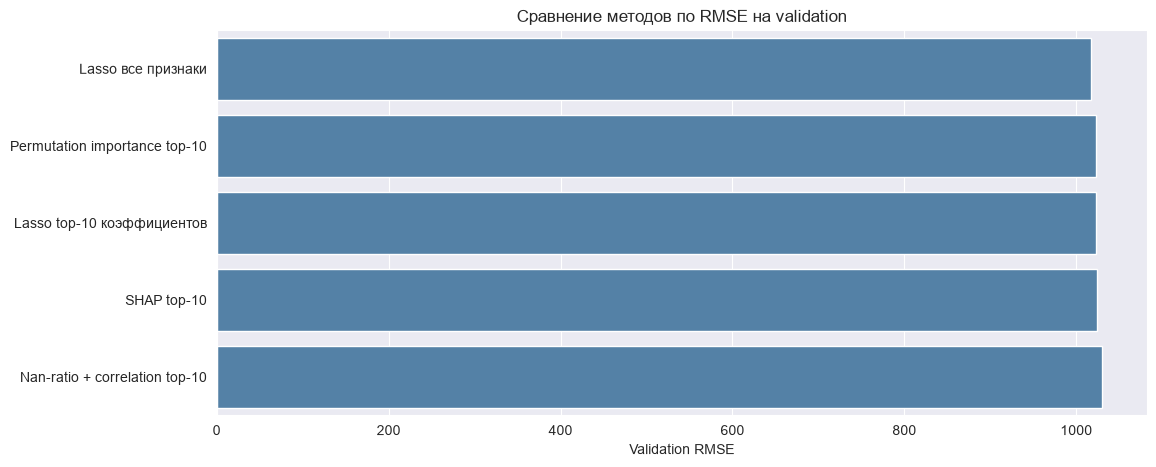

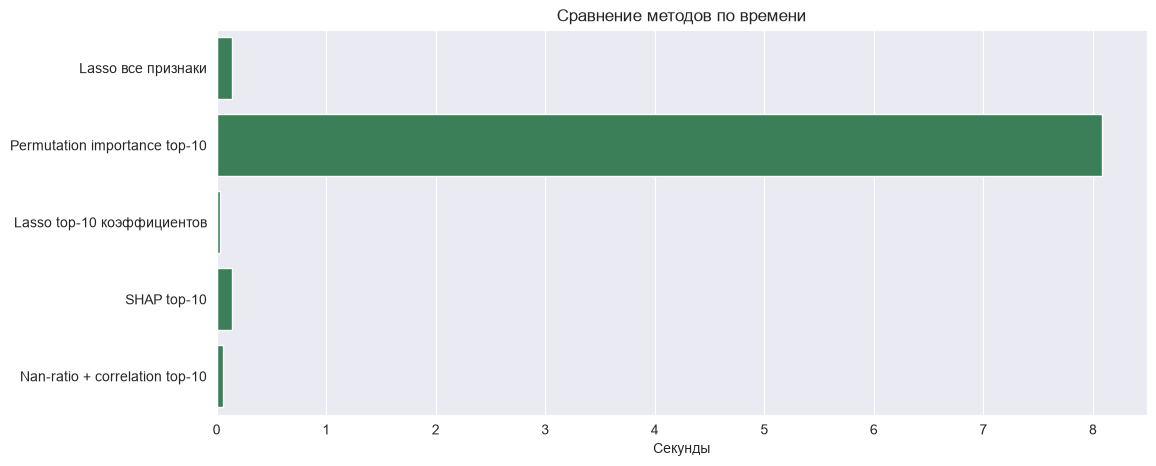

In [105]:
metric_columns = ['train_MAE', 'validation_MAE', 'test_MAE', 'train_RMSE', 'validation_RMSE', 'test_RMSE', 'train_R2', 'validation_R2', 'test_R2']

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_short,
    x='validation_RMSE',
    y='method',
    color='steelblue',
)
plt.title('Сравнение методов по RMSE на validation')
plt.xlabel('Validation RMSE')
plt.ylabel('')
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_short,
    x='total_time_sec',
    y='method',
    color='seagreen',
)
plt.title('Сравнение методов по времени')
plt.xlabel('Секунды')
plt.ylabel('')
plt.show()

## Вывод

1. Базовая `Lasso` на всех нормализованных признаках дает контрольное качество.
2. `Lasso top-10` обычно почти не уступает полной модели, потому что Lasso уже зануляет или ослабляет малополезные признаки.
3. Простой метод `nan-ratio + correlation` самый быстрый и хорошо объяснимый, но он учитывает только индивидуальную связь признака с `price`, поэтому может проигрывать методам, которые смотрят на модель целиком.
4. `Permutation importance` медленнее, зато оценивает реальный вклад признака в качество уже обученной модели на validation.
5. `SHAP` дает интерпретируемые вклады признаков в предсказания. Для линейной модели результат обычно близок к важности по коэффициентам, особенно если признаки нормализованы.

В качестве основного решения для этого датасета разумно выбрать `Lasso top-10` или `SHAP top-10`: они сохраняют качество, оставляют компактный набор признаков и хорошо интерпретируются. Если важнее скорость и простота, подойдет `nan-ratio + correlation`. Если важнее проверка влияния признака на метрику модели, лучше использовать `Permutation importance`.